# First Step

## codigo

In [275]:
import pandas as pd

path1 = 'C:/Users/Hychiro/Documents/Mestrado/Mestrado/Mestrado/Review/SLR-BCI-temporal-filters/structured_data/filter_final_output.csv'

dffilters = pd.read_csv(path1)

print(dffilters.head())

                               Filter_type  \
0           hibrido (espaco-temporal, fir)   
1                   bandpass (butterworth)   
2         low-pass (butterworth 4th ordem)   
3  bandpass (butterworth, busca exaustiva)   
4                filterbank (chebyshev ii)   

                                           Frequency  \
0                                      nao se aplica   
1                                               7-30   
2                                                 50   
3                                      nao se aplica   
4  4-8, 8-12, 12-16, 16-20, 20-24, 24-28, 28-32, ...   

                                              Titulo  Ano de Publicacao  \
0  Common spatio-time-frequency patterns for moto...               2013   
1  Common spatio-time-frequency patterns for moto...               2013   
2  Common spatio-time-frequency patterns for moto...               2013   
3  Common spatio-time-frequency patterns for moto...               2013   
4  Common s

In [276]:
path2 = 'C:/Users/Hychiro/Documents/Mestrado/Mestrado/Mestrado/Review/SLR-BCI-temporal-filters/structured_data/datasets_final_output.csv'

dfdatasets = pd.read_csv(path2)

print(dfdatasets.head())

                                              Titulo   Fonte  \
0  Common spatio-time-frequency patterns for moto...  Scopus   
1  Common spatio-time-frequency patterns for moto...  Scopus   
2  A hybrid EEG-fNIRS BCI: Motor imagery for EEG ...    IEEE   
3  Motor imagery classification by means of sourc...  Scopus   
4  A Graph-Based Feature Extraction Algorithm Tow...    IEEE   

         Datasets_used  Ano de Publicacao Classes  \
0        bci c iii iva               2013       2   
1           bci c iv i               2013       2   
2              privado               2014       2   
3  dataset allen osman               2004       2   
4              privado               2021       2   

                                          Resultados Metrics_used  
0  bci c iii iva -> csp: 87.9, csp-exh: 91.3, css...     accuracy  
1  bci c iii iva -> csp: 87.9, csp-exh: 91.3, css...     accuracy  
2  dataset proprio, 4 sujeitos, commom state vs r...          NaN  
3  the eeg data consisti

In [277]:
filters_unique = dffilters['Filter_type'].unique()
filters = dffilters['Filter_type'].tolist()
print("Unique filter types:", filters_unique) 

datasets = dfdatasets['Datasets_used'].unique()

print("Unique datasets used:", datasets)

Unique filter types: ['hibrido (espaco-temporal, fir)' 'bandpass (butterworth)'
 'low-pass (butterworth 4th ordem)'
 'bandpass (butterworth, busca exaustiva)' 'filterbank (chebyshev ii)'
 'filterbank (fir  41th ordem)' 'bandpass (indeterminado)'
 'bandpass (butterworth 5th ordem)' 'wavelet (cmw)'
 'filtro proprio (morphology)' 'bandpass (anti-aliasing?)'
 'integrado (convolucao temporal)' 'wavelet (wpd)'
 'filterbank (indeterminado)' 'wavelet (dwt)'
 'morphological multiresolution analysis (haar-type morphology)'
 'integrado (kalman filter+tensor)' 'wavelet (wt)' 'stft'
 'bandstop (indeterminado)' 'low-pass (indeterminado)'
 'high-pass (indeterminado)' 'integrado (etapa do cd3net)'
 'filterbank (butterworth)' 'wavelet (wtt)' 'emd' 'bandpass (fir)'
 'bandpass (fir 500th ordem)' 'bandpass (butterworth 4th ordem)'
 'high-pass (butterworth 4th ordem)' 'bandpass (fir anti-aliasing)'
 'hibrido (espaco-temporal, fir 16th ordem)'
 'hibrido (espaco-temporal, fir 40th ordem)'
 'integrado (convol

In [278]:
# number of unique filter types
print("Number of unique filter types:", len(filters_unique))
print("Number of unique datasets used:", len(datasets))

Number of unique filter types: 138
Number of unique datasets used: 40


In [279]:
# retirar tudo depois dos pareteses dos nomes do filters
filter2 = [f.split('(')[0].strip() if '(' in f else f for f in filters]
filter2_unique = list(set(filter2))
print("Filter types without parentheses:", filter2_unique)
print("Number of unique filter types without parentheses:", len(filter2_unique))
print("Number of unique datasets used:", len(datasets))


Filter types without parentheses: ['eemd', 'decomposition', 'mwtft', 'bandpass', 'espectrograma', 'hibrido', 'tvar', 'mst', 'hhtf', 'integrado', 'wavelet', 'bmflc', 'wigner-ville', 'smoothing', 'hht', 'morphological multiresolution analysis', 'stft', 'filtro proprio', 'memd', 'high-pass', 'cqt', 'st', 'essdm', 'low-pass', 'gt', 'hilbert', 'filterbank', 'matching pursuit', 'vmd', 'emd', 'bandstop', 'cwd']
Number of unique filter types without parentheses: 32
Number of unique datasets used: 40


In [280]:
import matplotlib.pyplot as plt
from collections import Counter

list_of_emd = ["vmd", "emd", "eemd", "hht", "memd", "hhtf"]

filter2_segregated = [
    "emd" if f.lower() in list_of_emd else f
    for f in filter2
]

# Conta a frequência de cada filtro
filter_counts = Counter(filter2_segregated)

# Total de filtros
total = sum(filter_counts.values())

# Agrupa filtros com menos de 1% em "Other"
filter_counts = Counter({
    f: count
    for f, count in filter_counts.items()
    if count / total >= 0.01
})

other_count = total - sum(filter_counts.values())

if other_count > 0:
    filter_counts["Other"] = other_count

print(filter_counts)



# Ordena do maior para o menor
sorted_counts = dict(
    sorted(
        filter_counts.items(),
        key=lambda x: x[1],
        reverse=True
    )
)

# Move "Other" para o final
if "Other" in sorted_counts:
    other = sorted_counts.pop("Other")
    sorted_counts["Other"] = other




Counter({'bandpass': 225, 'wavelet': 158, 'filterbank': 143, 'integrado': 61, 'emd': 50, 'stft': 38, 'Other': 27, 'bandstop': 20, 'hibrido': 15, 'hilbert': 12, 'low-pass': 10, 'high-pass': 8})


## grafico analise de tipagem

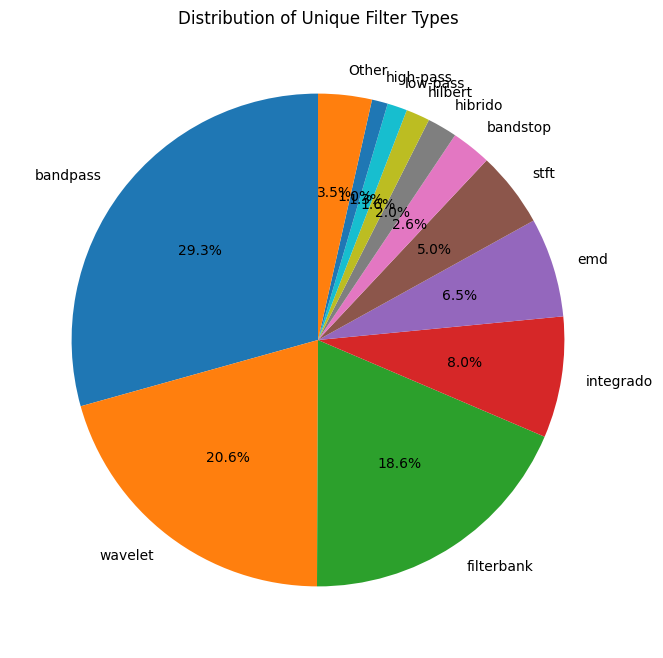

In [281]:
plt.figure(figsize=(8, 8))

plt.pie(
    sorted_counts.values(),
    labels=sorted_counts.keys(),
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Unique Filter Types')
plt.show()

## codigo

In [282]:

filters_and_times = dffilters[['Filter_type', 'Ano de Publicacao']].values.tolist()

list_of_emd = ["vmd", "emd", "eemd", "hht", "memd", "hhtf"]

filters_and_times = dffilters[
    ['Filter_type', 'Ano de Publicacao']
].values.tolist()


# Remove informações entre parênteses
filters_and_times = [
    (
        f.split('(')[0].strip() if '(' in str(f) else f,
        year
    )
    for f, year in filters_and_times
]

# Normaliza os métodos EMD
filters_and_times = [
    (
        "emd" if str(f).lower() in list_of_emd else f,
        year
    )
    for f, year in filters_and_times
]

# Conta a frequência dos filtros
filter_counts = Counter(
    f for f, year in filters_and_times
)
    

total = sum(filter_counts.values())

# Filtros com >= 1%
main_filters = {
    f: count
    for f, count in filter_counts.items()
    if count / total >= 0.01
}

# Junta os demais em Other
other_count = total - sum(main_filters.values())

if other_count > 0:
    main_filters["Other"] = other_count

# Ordena do maior para o menor
sorted_counts = dict(
    sorted(
        main_filters.items(),
        key=lambda x: x[1],
        reverse=True
    )
)

# Other sempre por último
if "Other" in sorted_counts:
    other = sorted_counts.pop("Other")
    sorted_counts["Other"] = other

print(sorted_counts)

df_plot = pd.DataFrame(
    filters_and_times,
    columns=["Filter_type", "Ano de Publicacao"]
)

# Agrupa os filtros < 1% em Other
main_filter_names = set(sorted_counts.keys()) - {"Other"}

df_plot["Filter_type"] = df_plot["Filter_type"].apply(
    lambda x: x if x in main_filter_names else "Other"
)

# Conta publicações por ano e filtro
df_year = (
    df_plot
    .groupby(["Ano de Publicacao", "Filter_type"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# Mantém a mesma ordem da pizza
df_year = df_year.reindex(
    columns=sorted_counts.keys(),
    fill_value=0
)



{'bandpass': 225, 'wavelet': 158, 'filterbank': 143, 'integrado': 61, 'emd': 50, 'stft': 38, 'bandstop': 20, 'hibrido': 15, 'hilbert': 12, 'low-pass': 10, 'high-pass': 8, 'Other': 27}


## grafico analise de tipagem no tempo

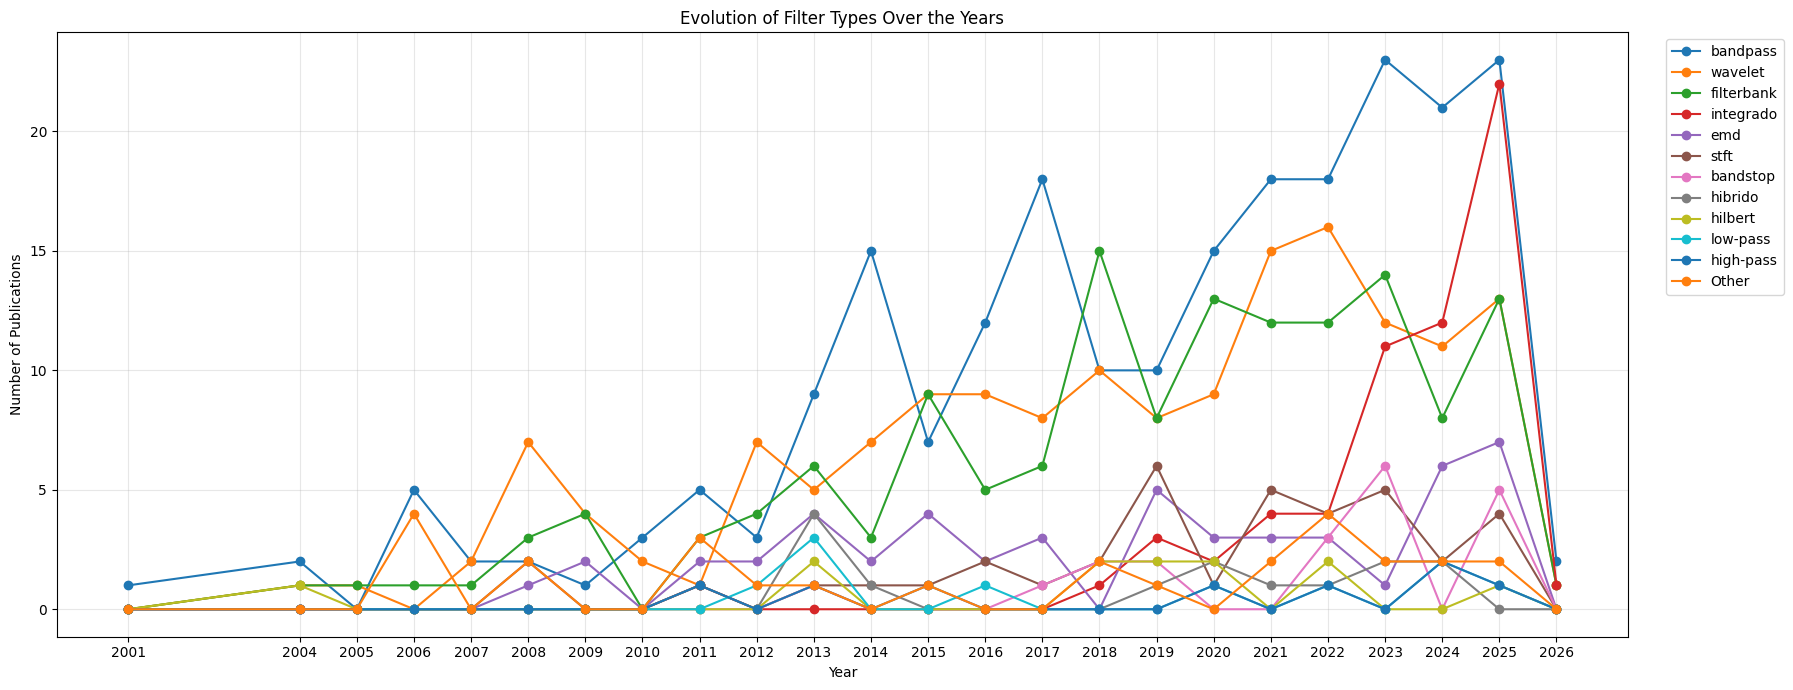

In [283]:
# Gráfico
plt.figure(figsize=(18, 7))

for filter_type in df_year.columns:
    plt.plot(
        df_year.index,
        df_year[filter_type],
        marker="o",
        label=filter_type
    )

plt.xlabel("Year")
plt.ylabel("Number of Publications")
plt.title("Evolution of Filter Types Over the Years")

plt.xticks(df_year.index)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

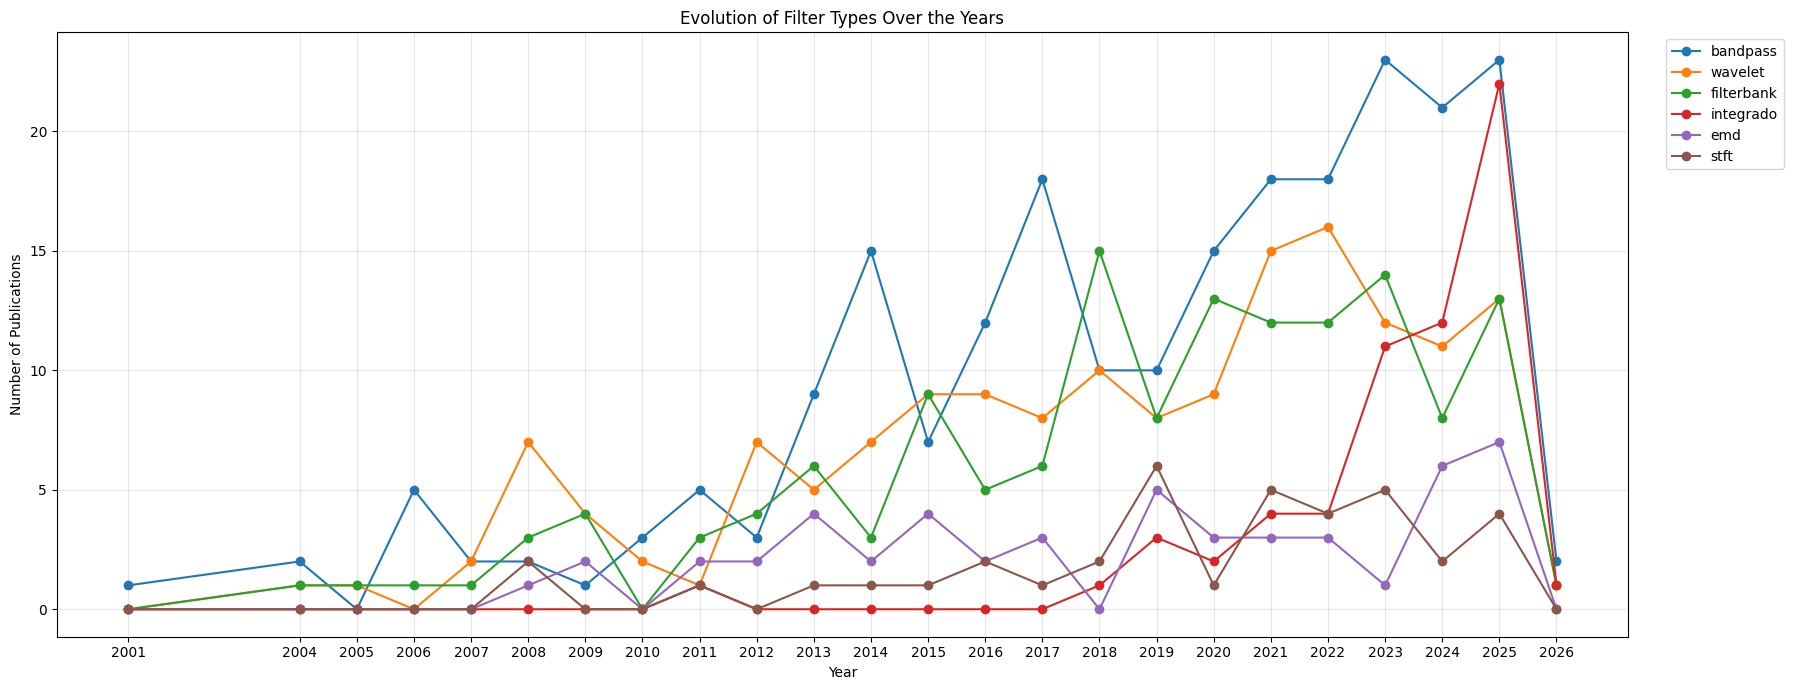

In [284]:
# Gráfico
plt.figure(figsize=(18, 7))
counter = 0
for filter_type in df_year.columns:
    plt.plot(
        df_year.index,
        df_year[filter_type],
        marker="o",
        label=filter_type
    )
    if counter == 5:
        break
    counter += 1

plt.xlabel("Year")
plt.ylabel("Number of Publications")
plt.title("Evolution of Filter Types Over the Years")

plt.xticks(df_year.index)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

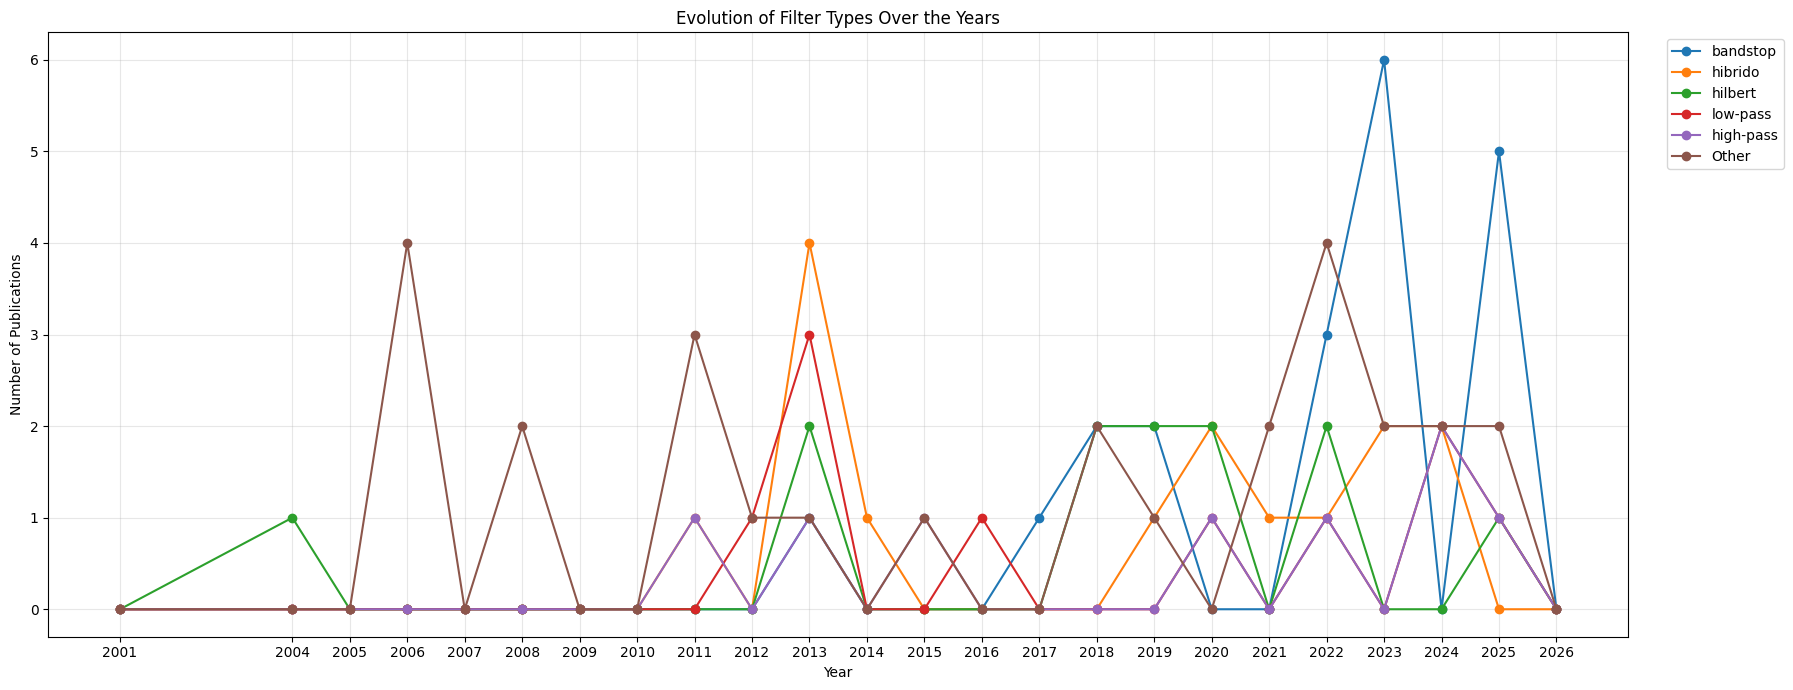

In [285]:
# Gráfico
plt.figure(figsize=(18, 7))
counter = 0
for filter_type in df_year.columns:
    if counter >= 6:
        plt.plot(
            df_year.index,
            df_year[filter_type],
            marker="o",
            label=filter_type
        )
    if counter == 12:
        break
    counter += 1

plt.xlabel("Year")
plt.ylabel("Number of Publications")
plt.title("Evolution of Filter Types Over the Years")

plt.xticks(df_year.index)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Codigo

In [286]:
import re

def normalizar_bandpass(filtro):
    filtro = filtro.strip().lower()
    filtro = re.sub(r"\s+\d+th.*$", ")", filtro)

    return filtro.strip()


def normalizar_filterbank(filtro):
    filtro = filtro.strip().lower()
    filtro = re.sub(r"\s+\d+th.*$", ")", filtro)

    return filtro


import re


def normalizar_emd(filtro):
    filtro = filtro.strip().lower()
    if "memd" in filtro:
        if "masking" in filtro:
            return "masking emd"
        else:
            return "multivariate emd"

    if "eemd" in filtro:
        return "eemd"

    if "emd" in filtro or filtro.endswith("md"):
        if "ht" in filtro:
            return filtro.split("(")[0].strip()

        return "emd"

    return filtro


def normalizar_wavelet(filtro):
    filtro = filtro.strip().lower()
    return filtro.strip()


def normalizar_hibrido(filtro):
    filtro = filtro.strip().lower()

    if "hibrido" in filtro:
        return "hibrido"

    return filtro


def normalizar_integrado(filtro):
    filtro = filtro.strip().lower()
    
    if "integrado" in filtro:
        return "integrado"

    return filtro

def normalizar_filtro(filtro):
    filtro_lower = filtro.strip().lower()

    if "bandpass" in filtro_lower:
        return normalizar_bandpass(filtro)

    elif "filterbank" in filtro_lower:
        return normalizar_filterbank(filtro)
    
    elif "wavelet" in filtro_lower:
        return normalizar_wavelet(filtro)

    elif "md" in filtro_lower:
        return normalizar_emd(filtro)

    elif "hibrido" in filtro_lower:
        return normalizar_hibrido(filtro)

    elif "integrado" in filtro_lower:
        return normalizar_integrado(filtro)
    return filtro_lower


In [287]:

filters_and_times2 = dffilters[['Filter_type', 'Ano de Publicacao']].values.tolist()


filters_and_times2 = dffilters[
    ['Filter_type', 'Ano de Publicacao']
].values.tolist()


filters_and_times2 = [
    (normalizar_filtro(filtro), ano)
    for filtro, ano in filters_and_times2
]

# Conta a frequência dos filtros
filters_and_times_count = Counter(
    f for f, year in filters_and_times2
)
    
total = sum(filters_and_times_count.values())

main_filters2 = {
    f: count
    for f, count in filters_and_times_count.items()
    if count / total >= 0.005
}
# Junta os demais em Other
other_count = total - sum(main_filters2.values())

if other_count > 0:
    main_filters2["Other"] = other_count

# Ordena do maior para o menor
sorted_counts2 = dict(
    sorted(
        main_filters2.items(),
        key=lambda x: x[1],
        reverse=True
    )
)

# Other sempre por último
if "Other" in sorted_counts2:
    other = sorted_counts2.pop("Other")
    sorted_counts2["Other"] = other
print("aqui")
print(sorted_counts2)
print(filters_and_times2)
print("aqui")

df_plot2 = pd.DataFrame(
    filters_and_times2,
    columns=["Filter_type", "Ano de Publicacao"]
)
# Agrupa os filtros < 1% em Other
main_filter_names2 = set(sorted_counts2.keys()) - {"Other"}

df_plot2["Filter_type"] = df_plot2["Filter_type"].apply(
    lambda x: x if x in main_filter_names2 else "Other"
)

# Conta publicações por ano e filtro
df_year2 = (
    df_plot2
    .groupby(["Ano de Publicacao", "Filter_type"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# Mantém a mesma ordem da pizza
df_year2 = df_year2.reindex(
    columns=sorted_counts2.keys(),
    fill_value=0
)





aqui
{'bandpass (indeterminado)': 90, 'bandpass (butterworth)': 84, 'wavelet (dwt)': 59, 'integrado': 58, 'filterbank (chebyshev ii)': 48, 'filterbank (indeterminado)': 43, 'wavelet (cwt)': 39, 'stft': 38, 'filterbank (butterworth)': 33, 'emd': 24, 'wavelet (wt)': 18, 'bandpass (fir)': 18, 'hibrido': 15, 'wavelet (wpd)': 15, 'multivariate emd': 14, 'bandstop (notch)': 13, 'hilbert (ht)': 12, 'low-pass (indeterminado)': 7, 'filterbank (fir)': 6, 'bandpass (elliptic)': 6, 'wavelet (dt-cwt)': 6, 'bandstop (indeterminado)': 5, 'high-pass (indeterminado)': 5, 'bandpass (chebyshev ii)': 5, 'bandpass (iir)': 4, 'bandpass (equiripple)': 4, 'eemd': 4, 'decomposition (local cosine packets)': 4, 'st (stockwell transform)': 4, 'hht': 4, 'Other': 82}
[('hibrido', 2013), ('bandpass (butterworth)', 2013), ('low-pass (butterworth 4th ordem)', 2013), ('bandpass (butterworth, busca exaustiva)', 2013), ('filterbank (chebyshev ii)', 2013), ('filterbank (fir)', 2013), ('bandpass (indeterminado)', 2014), ('

## graficos com indeterminado

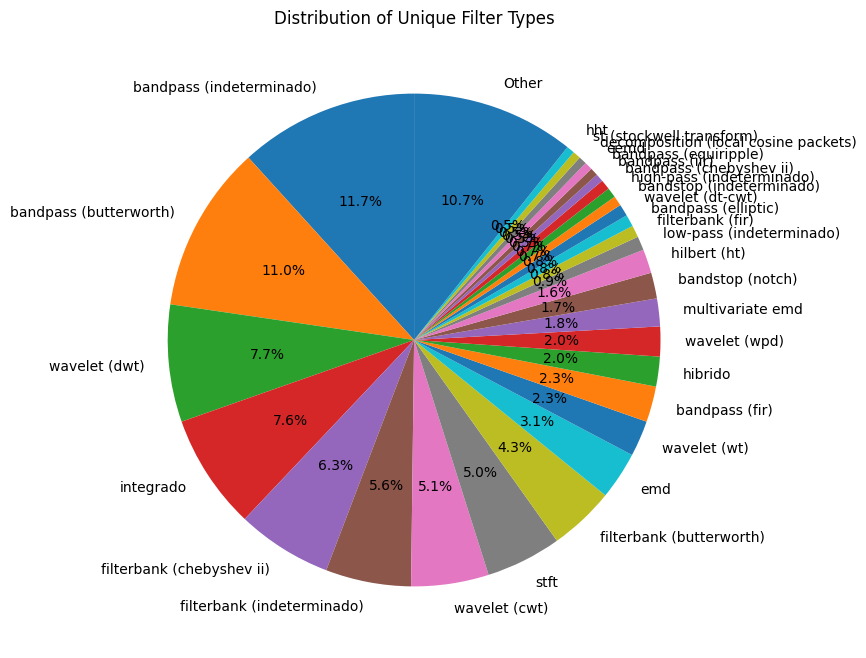

In [288]:
plt.figure(figsize=(8, 8))

plt.pie(
    sorted_counts2.values(),
    labels=sorted_counts2.keys(),
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Unique Filter Types')
plt.show()

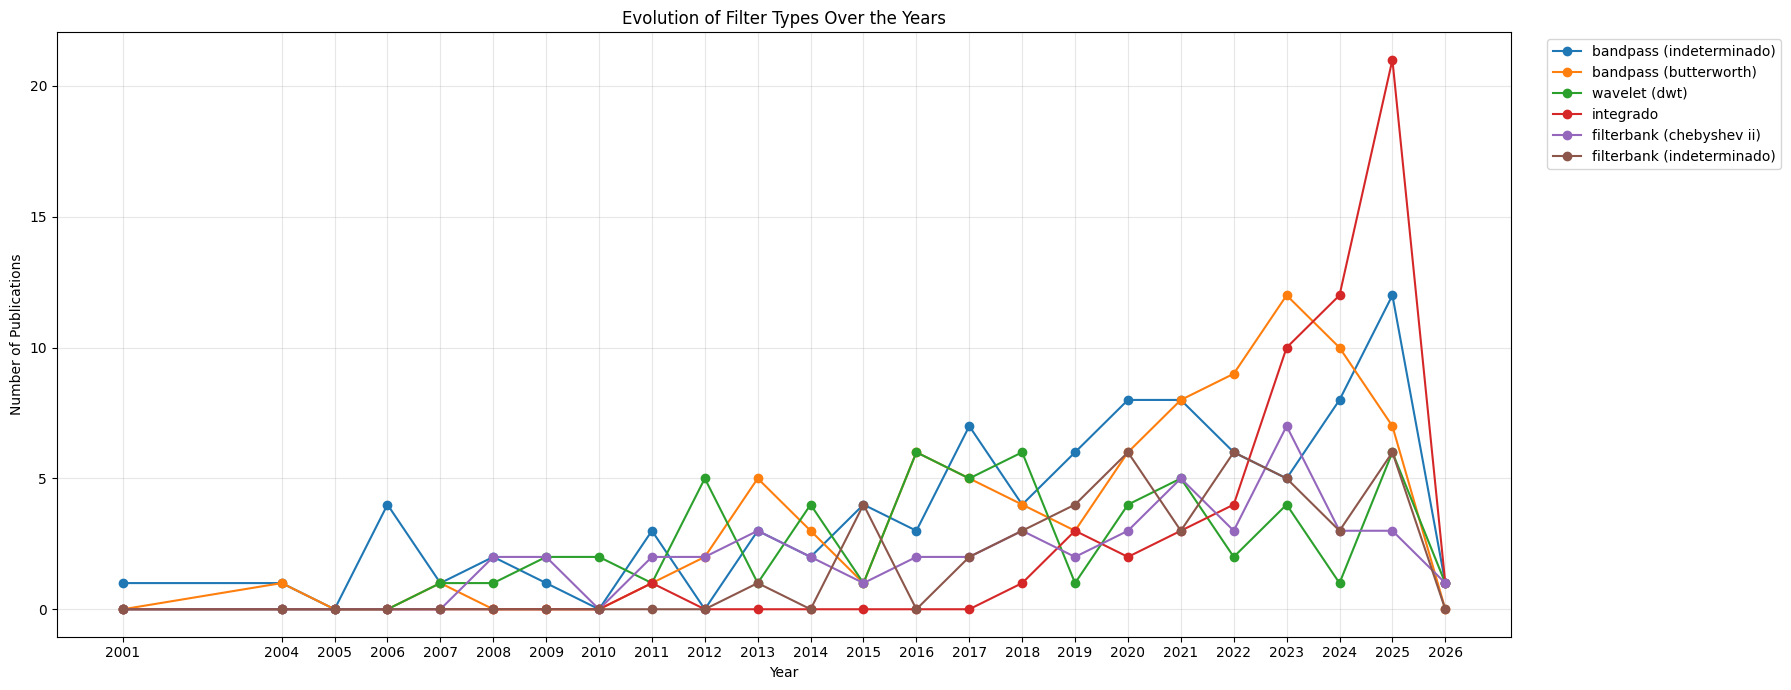

In [289]:
# Gráfico
plt.figure(figsize=(18, 7))
counter = 0
for filter_type in df_year2.columns:
    plt.plot(
        df_year2.index,
        df_year2[filter_type],
        marker="o",
        label=filter_type
    )
    if counter == 5:
        break
    counter += 1

plt.xlabel("Year")
plt.ylabel("Number of Publications")
plt.title("Evolution of Filter Types Over the Years")

plt.xticks(df_year2.index)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

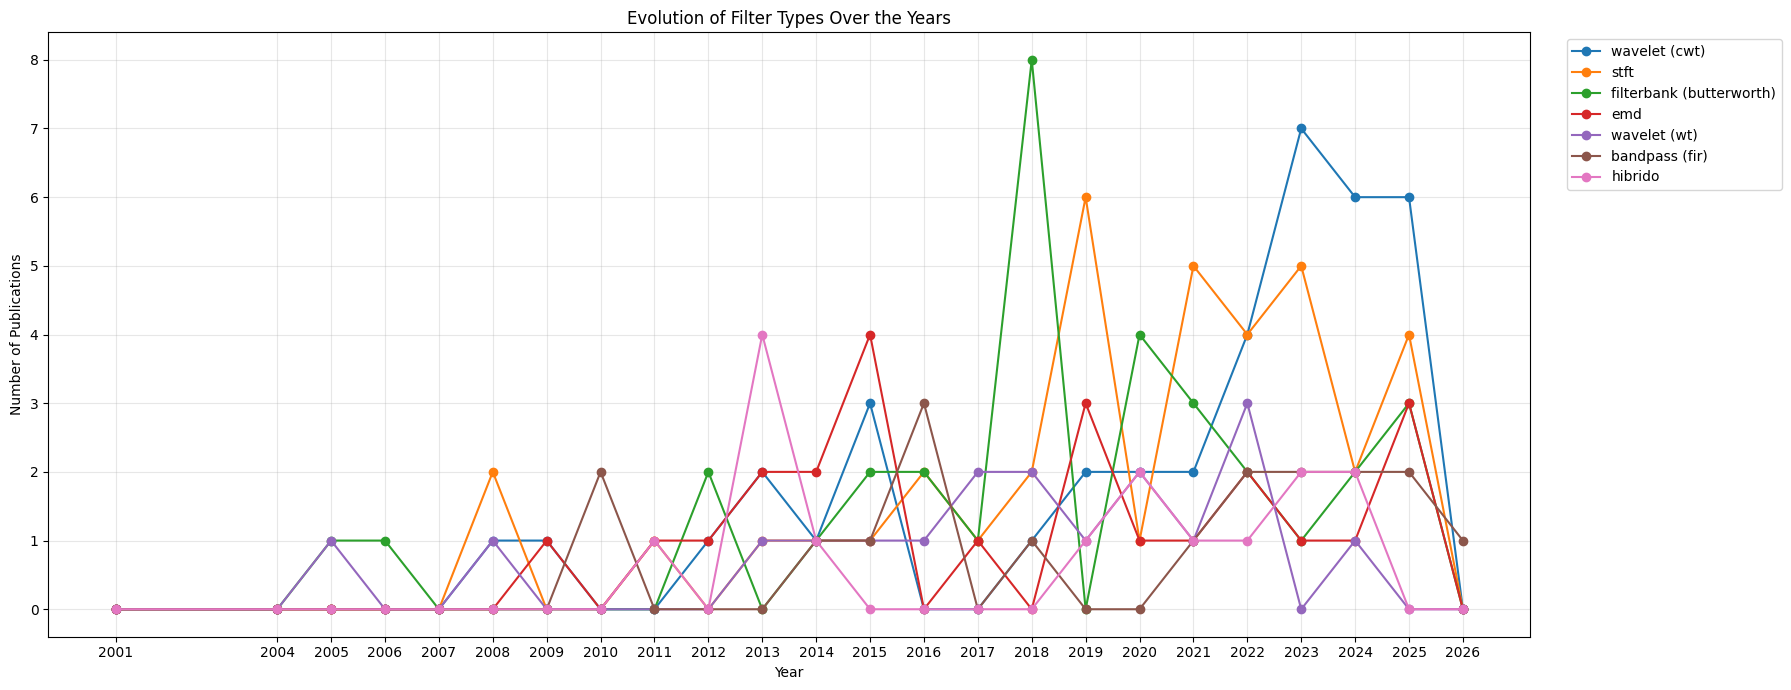

In [290]:
# Gráfico
plt.figure(figsize=(18, 7))
counter = 0
for filter_type in df_year2.columns:
    if counter >= 6:
        plt.plot(
            df_year2.index,
            df_year2[filter_type],
            marker="o",
            label=filter_type
        )
    if counter == 12:
        break
    counter += 1

plt.xlabel("Year")
plt.ylabel("Number of Publications")
plt.title("Evolution of Filter Types Over the Years")

plt.xticks(df_year2.index)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Codigo

In [291]:
def retirafiltros(filtro):
    filtro = filtro.strip().lower()

    if "hibrido" in filtro:
        return None

    if "indeterminado" in filtro:
        return None

    if "multivariate" in filtro:
        return None

    if "espaco-temporal" in filtro:
            return None

    return filtro

In [292]:

filters_and_times3 = dffilters[['Filter_type', 'Ano de Publicacao']].values.tolist()

filters_and_times3 = dffilters[
    ['Filter_type', 'Ano de Publicacao']
].values.tolist()




filters_without_spacial_data = [
    (retirafiltros(filtro), ano)
    for filtro, ano in filters_and_times3
    if retirafiltros(filtro) is not None
]

filters_without_spacial_data = [
    (normalizar_filtro(filtro), ano)
    for filtro, ano in filters_without_spacial_data
]

# Conta a frequência dos filtros
filters_without_spacial_data_and_times_count = Counter(
    f for f, year in filters_without_spacial_data
)
print (filters_without_spacial_data_and_times_count)

total = sum(filters_without_spacial_data_and_times_count.values())
print (total)
main_filters3 = {
    f: count
    for f, count in filters_without_spacial_data_and_times_count.items()
    if count / total >= 0.01
}
# Junta os demais em Other
other_count = total - sum(main_filters3.values())

if other_count > 0:
    main_filters3["Other"] = other_count

# Ordena do maior para o menor
sorted_counts3 = dict(
    sorted(
        main_filters3.items(),
        key=lambda x: x[1],
        reverse=True
    )
)

# Other sempre por último
if "Other" in sorted_counts3:
    other = sorted_counts3.pop("Other")
    sorted_counts3["Other"] = other
print("aqui")
print(sorted_counts3)
print(filters_without_spacial_data)
print("aqui")

df_plot3 = pd.DataFrame(
    filters_without_spacial_data,
    columns=["Filter_type", "Ano de Publicacao"]
)
# Agrupa os filtros < 1% em Other
main_filter_names3 = set(sorted_counts3.keys()) - {"Other"}

df_plot3["Filter_type"] = df_plot3["Filter_type"].apply(
    lambda x: x if x in main_filter_names3 else "Other"
)

# Conta publicações por ano e filtro
df_year3 = (
    df_plot3
    .groupby(["Ano de Publicacao", "Filter_type"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# Mantém a mesma ordem da pizza
df_year3 = df_year3.reindex(
    columns=sorted_counts3.keys(),
    fill_value=0
)


other_filters = {
     f: count
        for f, count in filters_without_spacial_data_and_times_count.items()
        if count / total <= 0.01
}
print(other_filters)

sortedOther_counts3 = dict(
    sorted(
        other_filters.items(),
        key=lambda x: x[1],
        reverse=True
    )
)
print(sortedOther_counts3) 


Counter({'bandpass (butterworth)': 84, 'wavelet (dwt)': 59, 'integrado': 58, 'filterbank (chebyshev ii)': 48, 'wavelet (cwt)': 39, 'stft': 38, 'filterbank (butterworth)': 33, 'emd': 24, 'wavelet (wt)': 18, 'bandpass (fir)': 18, 'wavelet (wpd)': 15, 'bandstop (notch)': 13, 'hilbert (ht)': 12, 'filterbank (fir)': 6, 'bandpass (elliptic)': 6, 'wavelet (dt-cwt)': 6, 'bandpass (chebyshev ii)': 5, 'bandpass (iir)': 4, 'bandpass (equiripple)': 4, 'eemd': 4, 'decomposition (local cosine packets)': 4, 'st (stockwell transform)': 4, 'hht': 4, 'wavelet (wpt)': 3, 'bandpass (chebyshev i)': 3, 'integrado (filterbank, sinc-conv)': 3, 'low-pass (butterworth 4th ordem)': 2, 'wavelet (cmw)': 2, 'wavelet (morlet)': 2, 'bandpass (kaiserwin)': 2, 'wavelet (sst)': 2, 'smoothing (gaussian, aplicado mapa tempo-frequencia)': 2, 'masking emd': 2, 'wavelet (modwt)': 2, 'wavelet (ewt)': 2, 'filterbank (fir, coefficient decimation)': 2, 'bandpass (butterworth, busca exaustiva)': 1, 'filtro proprio (morphology)': 

## grafico sem indeterminado

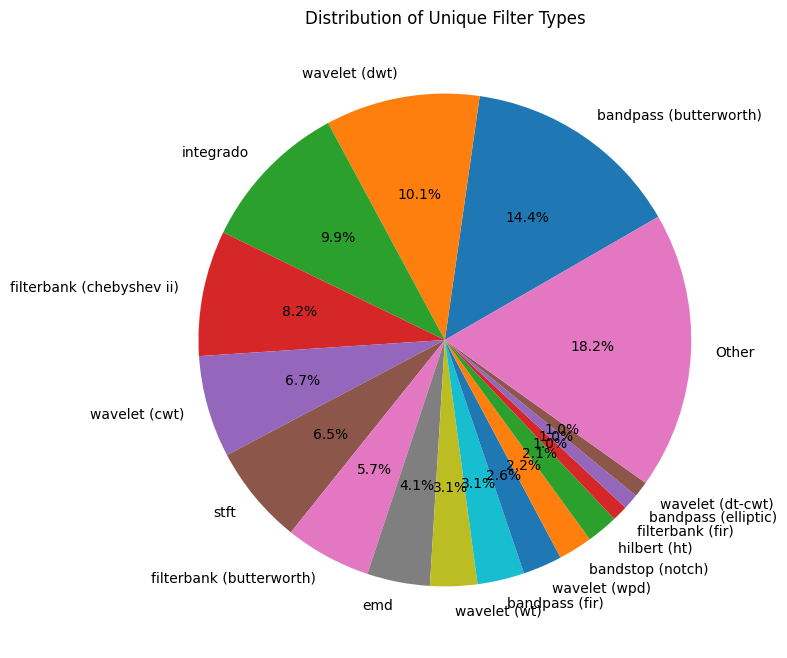

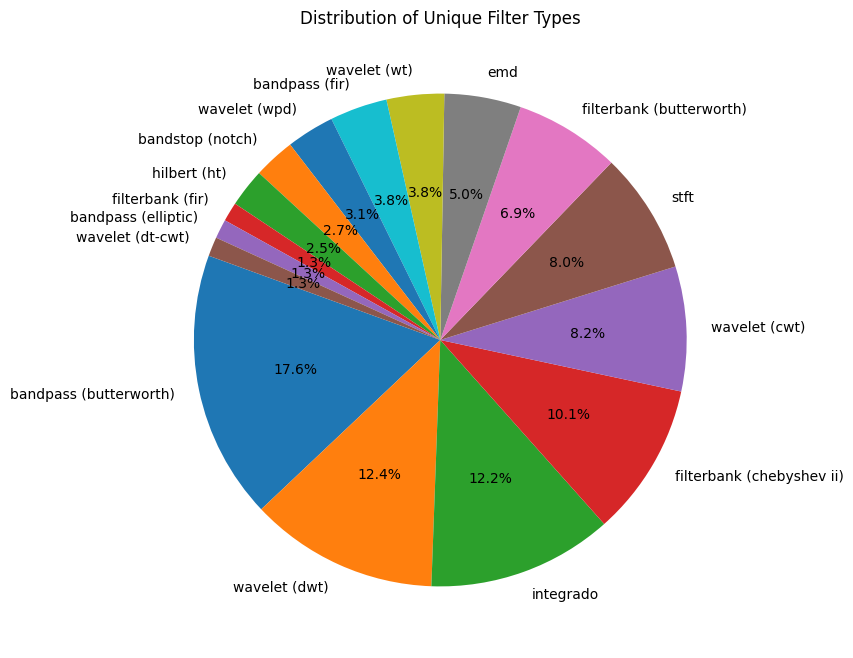

In [293]:
plt.figure(figsize=(8, 8))

plt.pie(
    sorted_counts3.values(),
    labels=sorted_counts3.keys(),
    autopct='%1.1f%%',
    startangle=30
)

plt.title('Distribution of Unique Filter Types')
plt.show()

sorted_counts3.pop("Other", None)

plt.figure(figsize=(8, 8))

plt.pie(
    sorted_counts3.values(),
    labels=sorted_counts3.keys(),
    autopct='%1.1f%%',
    startangle=160
)

plt.title('Distribution of Unique Filter Types')
plt.show()

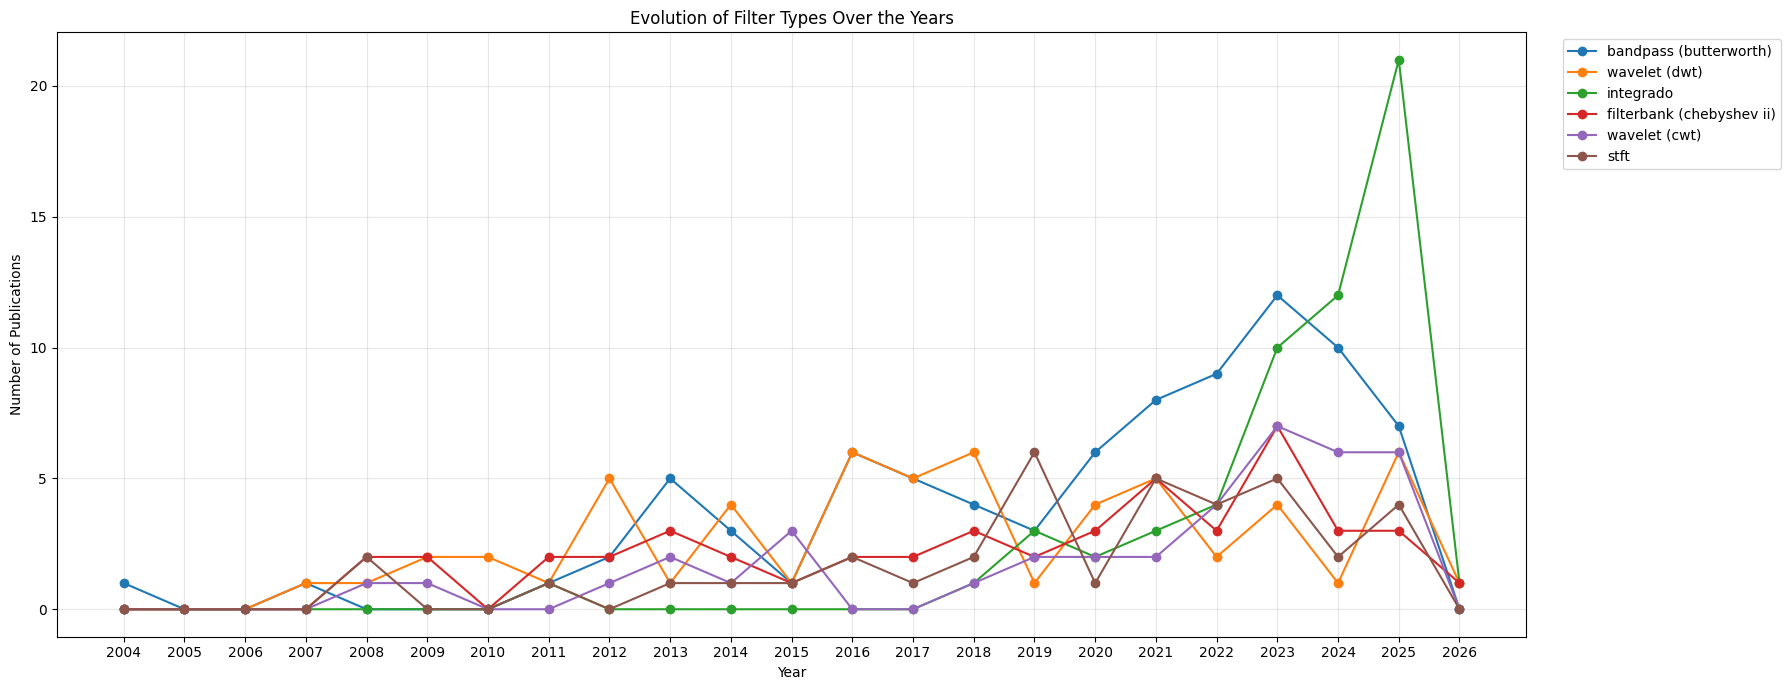

In [294]:
# Gráfico
plt.figure(figsize=(18, 7))
counter = 0
for filter_type in df_year3.columns:
    plt.plot(
        df_year3.index,
        df_year3[filter_type],
        marker="o",
        label=filter_type
    )
    if counter == 5:
        break
    counter += 1

plt.xlabel("Year")
plt.ylabel("Number of Publications")
plt.title("Evolution of Filter Types Over the Years")

plt.xticks(df_year3.index)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

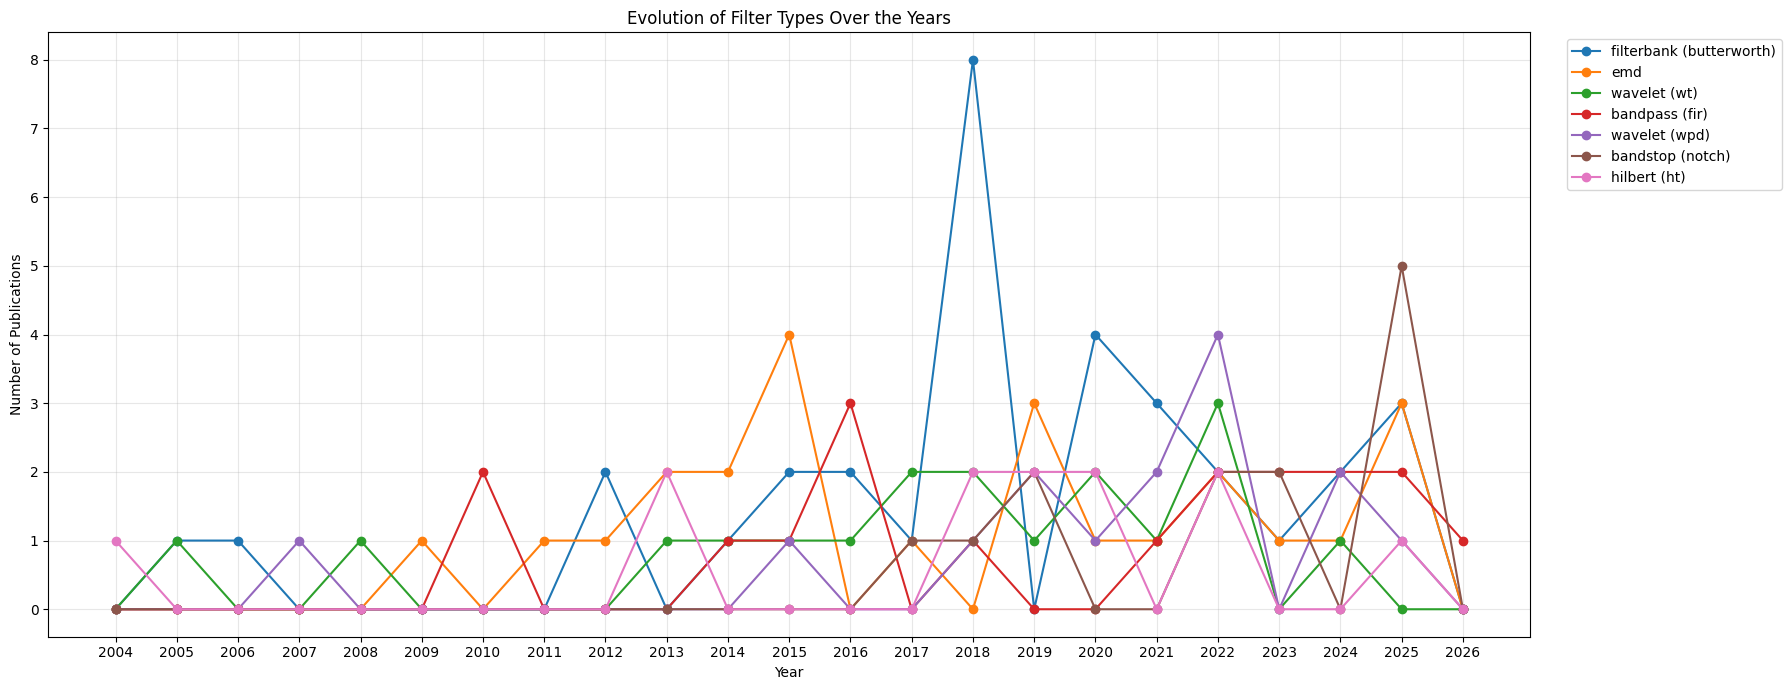

In [295]:
# Gráfico
plt.figure(figsize=(18, 7))
counter = 0
for filter_type in df_year3.columns:
    if counter >= 6:
        plt.plot(
            df_year3.index,
            df_year3[filter_type],
            marker="o",
            label=filter_type
        )
    if counter == 12:
        break
    counter += 1

plt.xlabel("Year")
plt.ylabel("Number of Publications")
plt.title("Evolution of Filter Types Over the Years")

plt.xticks(df_year3.index)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Codigo

In [ ]:
filters_and_times4 = dffilters[['Filter_type', 'Ano de Publicacao']].values.tolist()

filters_and_times4 = dffilters[
    ['Filter_type', 'Ano de Publicacao']
].values.tolist()

filters_and_times4 = [
    (normalizar_filtro(filtro), ano)
    for filtro, ano in filters_and_times4
]

wavelets = [
    (filtro, ano)
    for filtro, ano in filters_and_times4
    if "wavelet" in filtro.lower()
]

filterbanks = [
    (filtro, ano)
    for filtro, ano in filters_and_times4
    if "filterbank" in filtro.lower()
]

bandpass = [
    (filtro, ano)
    for filtro, ano in filters_and_times4
    if "bandpass" in filtro.lower()
]

bandpass = [
    (filtro, ano)
    for filtro, ano in bandpass
    if "filterbank" not in filtro.lower()
]


wavelets_count = Counter(
    f for f, year in wavelets
)

bandpass_count = Counter(
    f for f, year in bandpass
)

filterbanks_count = Counter(
    f for f, year in filterbanks
)
print("Wavelets")
print(wavelets_count)

print("bandpass")
print(bandpass_count)

print("filterbanks")
print(filterbanks_count)


Wavelets
Counter({'wavelet (dwt)': 59, 'wavelet (cwt)': 39, 'wavelet (wt)': 18, 'wavelet (wpd)': 15, 'wavelet (dt-cwt)': 6, 'wavelet (wpt)': 3, 'wavelet (cmw)': 2, 'wavelet (morlet)': 2, 'wavelet (sst)': 2, 'wavelet (modwt)': 2, 'wavelet (ewt)': 2, 'wavelet (wtt)': 1, 'wavelet (soft-threshold denoise)': 1, 'wavelet (swt)': 1, 'wavelet (complex-morlet)': 1, 'tvar (mwbf-rols, wavelet, tempo frequencia)': 1, 'wavelet (mewt, espaco-temporal)': 1, 'wavelet (mwt, espaco-temporal)': 1, 'wavelet (non-dyadic)': 1, 'wavelet (threshold denoising)': 1})
bandpass
Counter({'bandpass (indeterminado)': 90, 'bandpass (butterworth)': 84, 'bandpass (fir)': 18, 'bandpass (elliptic)': 6, 'bandpass (chebyshev ii)': 5, 'bandpass (iir)': 4, 'bandpass (equiripple)': 4, 'bandpass (chebyshev i)': 3, 'bandpass (kaiserwin)': 2, 'bandpass (butterworth, busca exaustiva)': 1, 'bandpass (anti-aliasing?)': 1, 'bandpass (fir anti-aliasing)': 1, 'bandpass (fir, coefficient decimation)': 1, 'bandpass (notch)': 1, 'bandpas

## graficos wavelet

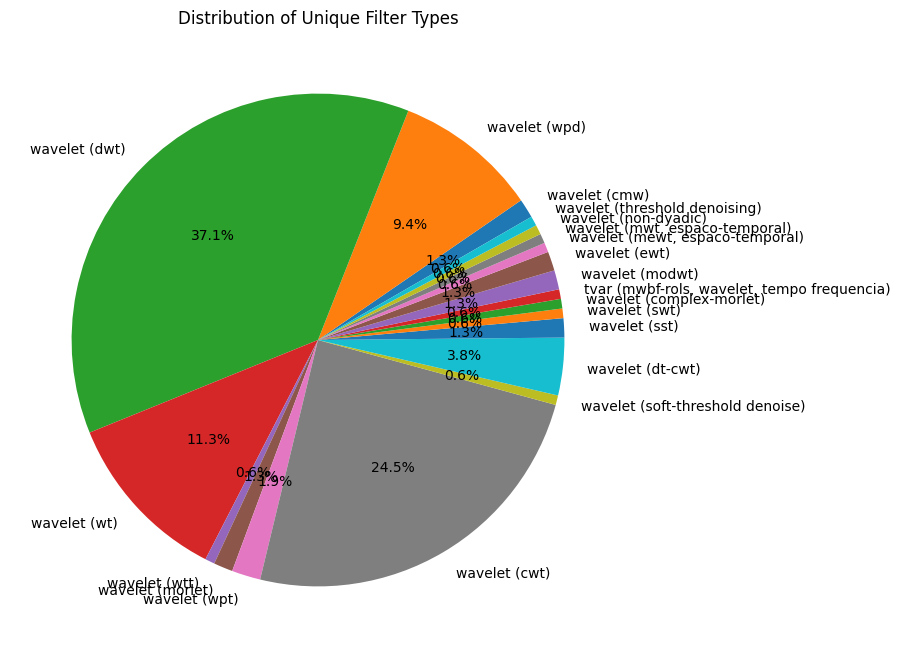

In [ ]:
plt.figure(figsize=(8, 8))

plt.pie(
    wavelets_count.values(),
    labels=wavelets_count.keys(),
    autopct='%1.1f%%',
    startangle=30
)

plt.title('Distribution of Unique Filter Types')
plt.show()

## graficos filterbank

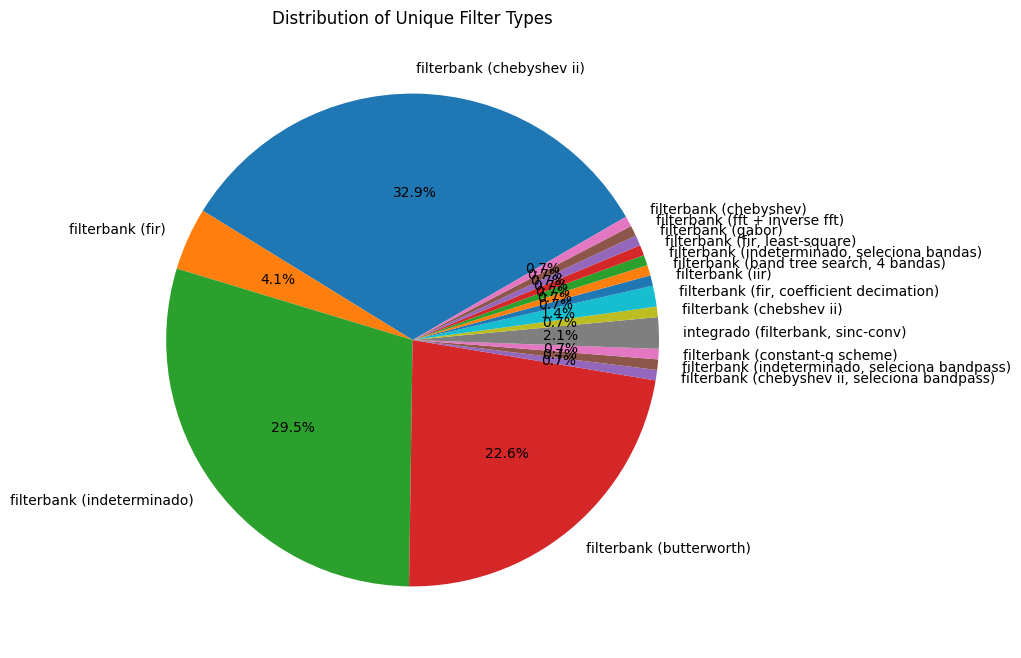

In [ ]:
plt.figure(figsize=(8, 8))

plt.pie(
    filterbanks_count.values(),
    labels=filterbanks_count.keys(),
    autopct='%1.1f%%',
    startangle=30
)

plt.title('Distribution of Unique Filter Types')
plt.show()

## graficos bandpass

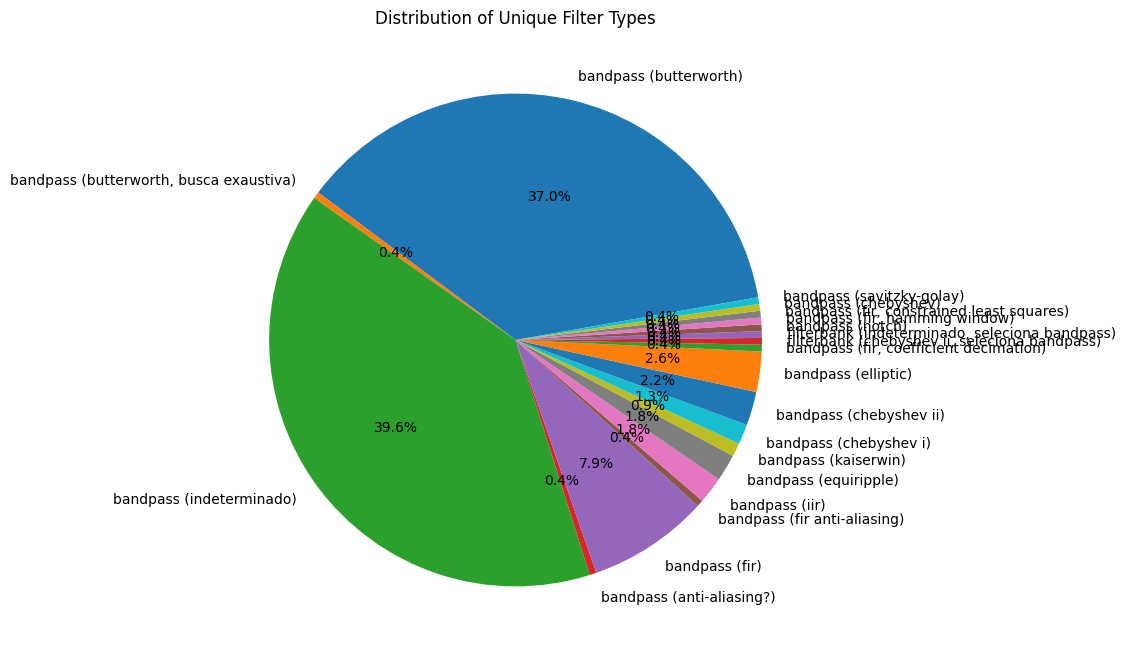

In [ ]:
plt.figure(figsize=(8, 8))

plt.pie(
    bandpass_count.values(),
    labels=bandpass_count.keys(),
    autopct='%1.1f%%',
    startangle=10
)

plt.title('Distribution of Unique Filter Types')
plt.show()